# Exploratory Data Analysis (EDA) - Crop Recommendation

## Section 12 — Educational Explanations

1. **What EDA means**: Exploratory Data Analysis is the process of examining and visualizing a dataset to understand its characteristics, structure, and potential anomalies.
2. **Why EDA is performed before ML**: Machine learning algorithms assume data is clean and representative. If you feed garbage into a model, you get garbage out. EDA helps us understand if the data is safe to learn from.
3. **What a histogram shows**: A histogram displays the frequency distribution of a continuous variable (like temperature). It helps us see where values cluster and how spread out they are.
4. **What a boxplot shows**: A boxplot shows the median, quartiles, and potential outliers in a localized visual summary.
5. **What an outlier means**: An outlier is an observation that lies an abnormal distance from other values in a random sample. It indicates extreme behavior.
6. **What correlation means**: Correlation measures the statistical relationship or association between two numerical variables.
7. **Difference between correlation and causation**: Correlation simply means two variables move together. It does not prove that changing one *causes* the other to change.
8. **Why class distribution matters**: If an algorithm sees 99 examples of rice and 1 example of maize, it will just guess rice every time. Balanced classes allow models to learn fair representations.
9. **Why we should not automatically delete outliers**: In agriculture, extreme values (like heavy rainfall) might be natural events, not sensor errors. Deleting them blindly harms the dataset's integrity.

## Section 11 — Feature Name Mapping

**Raw Name → Application Name**
- **N** → nitrogen
- **P** → phosphorus
- **K** → potassium
- **ph** → pH
- **label** → crop

*Note: We will not modify the raw CSV. This mapping is conceptual for a future controlled pipeline.*

## Section 1 — Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Keep raw data read-only
dataset_path = '../../datasets/Crop_recommendation.csv'

if not os.path.exists(dataset_path):
    print('ERROR: Dataset not found!')
else:
    df = pd.read_csv(dataset_path)
    print('Dataset Shape:', df.shape)
    print('\nColumn Names:', df.columns.tolist())
    print('\nData Types:\n', df.dtypes)
    print('\nMissing values summary:\n', df.isnull().sum())
    print('\nDuplicate rows count:', df.duplicated().sum())

df.head()

Dataset Shape: (2200, 8)

Column Names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data Types:
 N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

Missing values summary:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows count: 0


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [2]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


## Section 2 — Target Analysis
Analyzing the `label` target column.

Number of unique crops: 22
Crop names: <StringArray>
[       'rice',       'maize',    'chickpea', 'kidneybeans',  'pigeonpeas',
   'mothbeans',    'mungbean',   'blackgram',      'lentil', 'pomegranate',
      'banana',       'mango',      'grapes',  'watermelon',   'muskmelon',
       'apple',      'orange',      'papaya',     'coconut',      'cotton',
        'jute',      'coffee']
Length: 22, dtype: str

Samples per crop:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\909057746.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


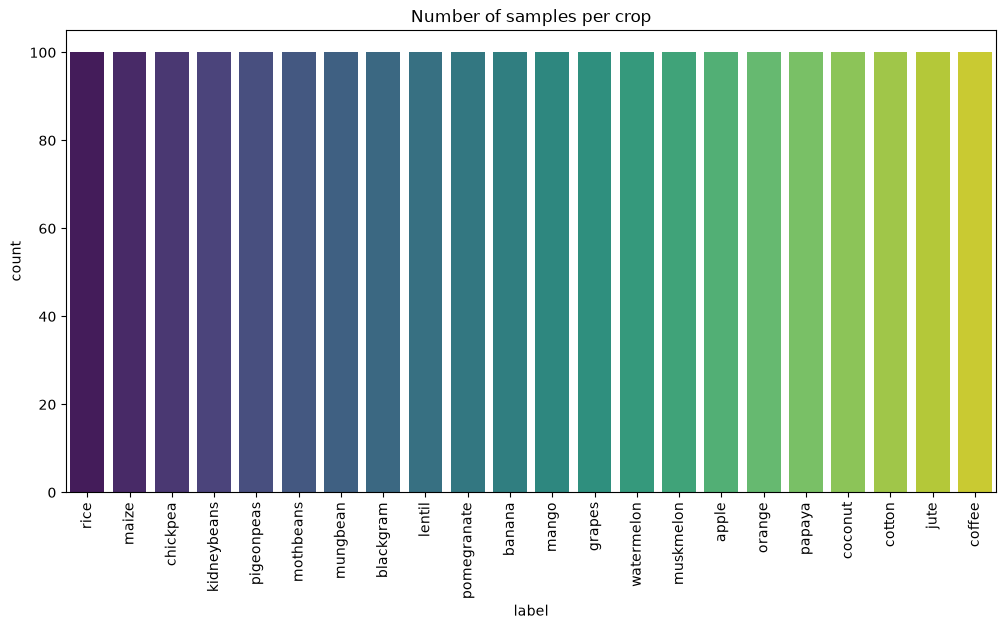

In [3]:
unique_crops = df['label'].unique()
print(f'Number of unique crops: {len(unique_crops)}')
print(f'Crop names: {unique_crops}')

print('\nSamples per crop:')
print(df['label'].value_counts())

plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='label', palette='viridis')
plt.xticks(rotation=90)
plt.title('Number of samples per crop')
plt.show()

## Section 3 — Numerical Feature Analysis

In [4]:
numeric_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

# Summary stats using describe
df[numeric_cols].describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## Section 4 — Distributions
Creating histograms and boxplots for all numerical features to inspect distributions.

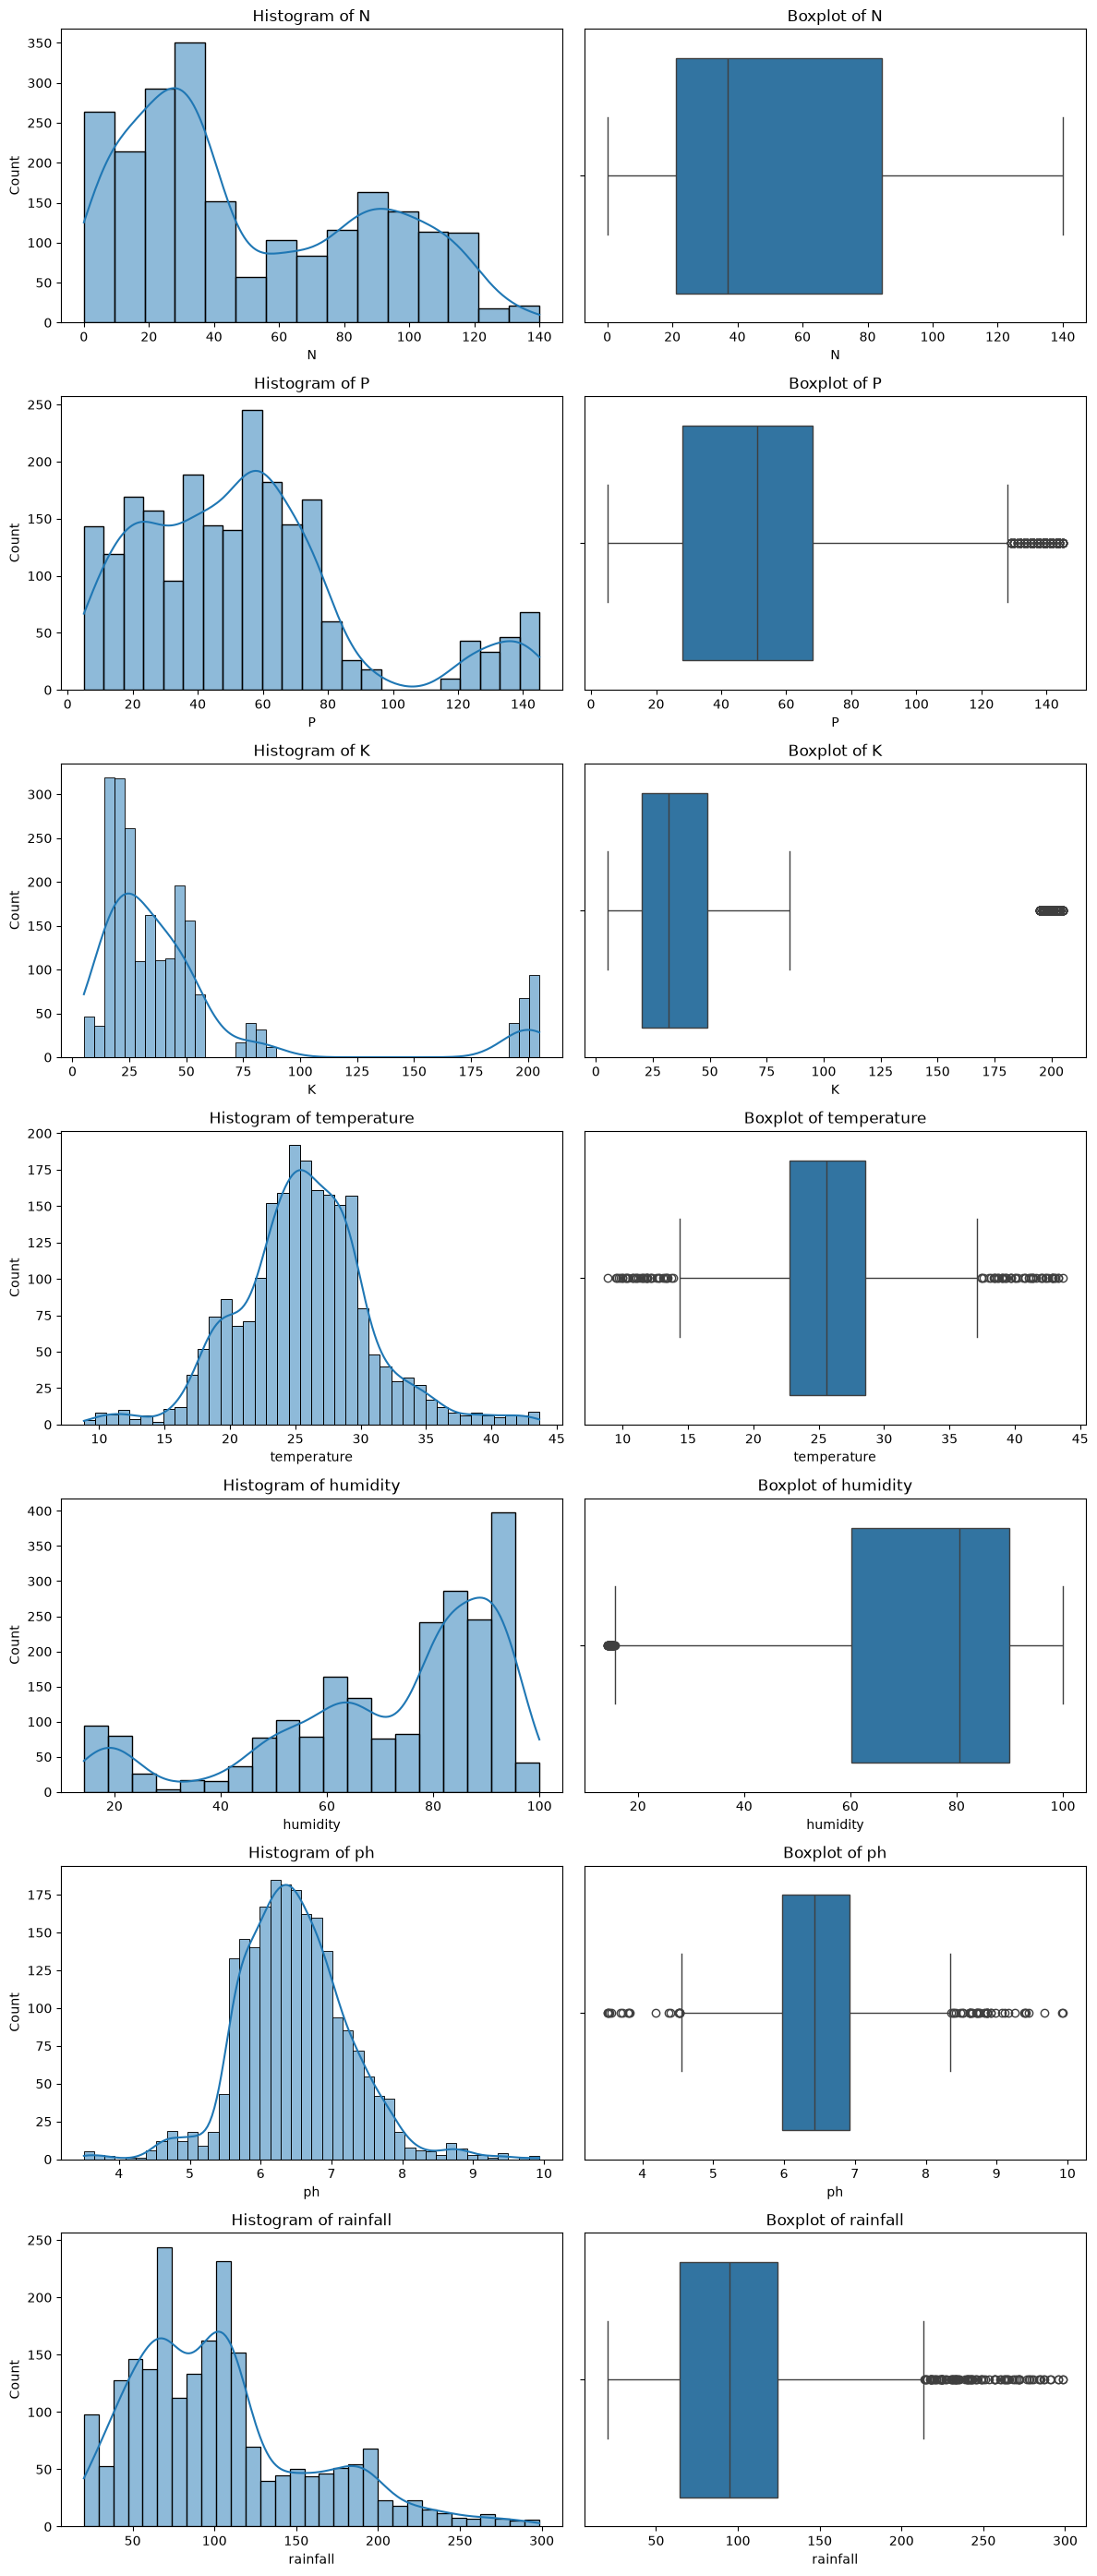

In [5]:
fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=2, figsize=(12, 4 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    # Histogram
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Histogram of {col}')
    
    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

## Section 5 — Outlier Inspection
Using the IQR rule to identify potential statistical outliers. *Note: Potential outlier does NOT automatically mean bad data.*

In [6]:
outlier_report = {}
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_report[col] = {'count': len(outliers), 'lower': lower_bound, 'upper': upper_bound}

for col, stats in outlier_report.items():
    print(f"{col}: {stats['count']} potential outliers (Lower: {stats['lower']:.2f}, Upper: {stats['upper']:.2f})")

print('\nExplanation: An agricultural measurement can legitimately be extreme and must be investigated before removal.')

N: 0 potential outliers (Lower: -73.88, Upper: 179.12)
P: 138 potential outliers (Lower: -32.00, Upper: 128.00)
K: 200 potential outliers (Lower: -23.50, Upper: 92.50)
temperature: 86 potential outliers (Lower: 14.08, Upper: 37.25)
humidity: 30 potential outliers (Lower: 15.73, Upper: 134.48)
ph: 57 potential outliers (Lower: 4.54, Upper: 8.35)
rainfall: 100 potential outliers (Lower: -25.02, Upper: 213.84)

Explanation: An agricultural measurement can legitimately be extreme and must be investigated before removal.


## Section 6 — Feature Correlation
Investigating linear association between numerical variables.

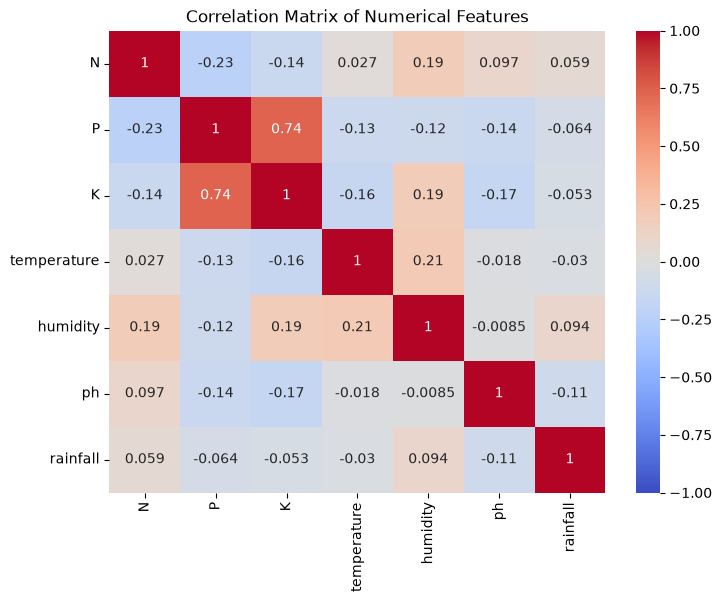

In [7]:
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## Section 7 — Crop-wise Analysis
Understanding whether different crops appear to have different feature patterns.

C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')
C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')


C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')
C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')


C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')
C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')


C:\Users\Harshit Patel\AppData\Local\Temp\ipykernel_28496\3435952551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')


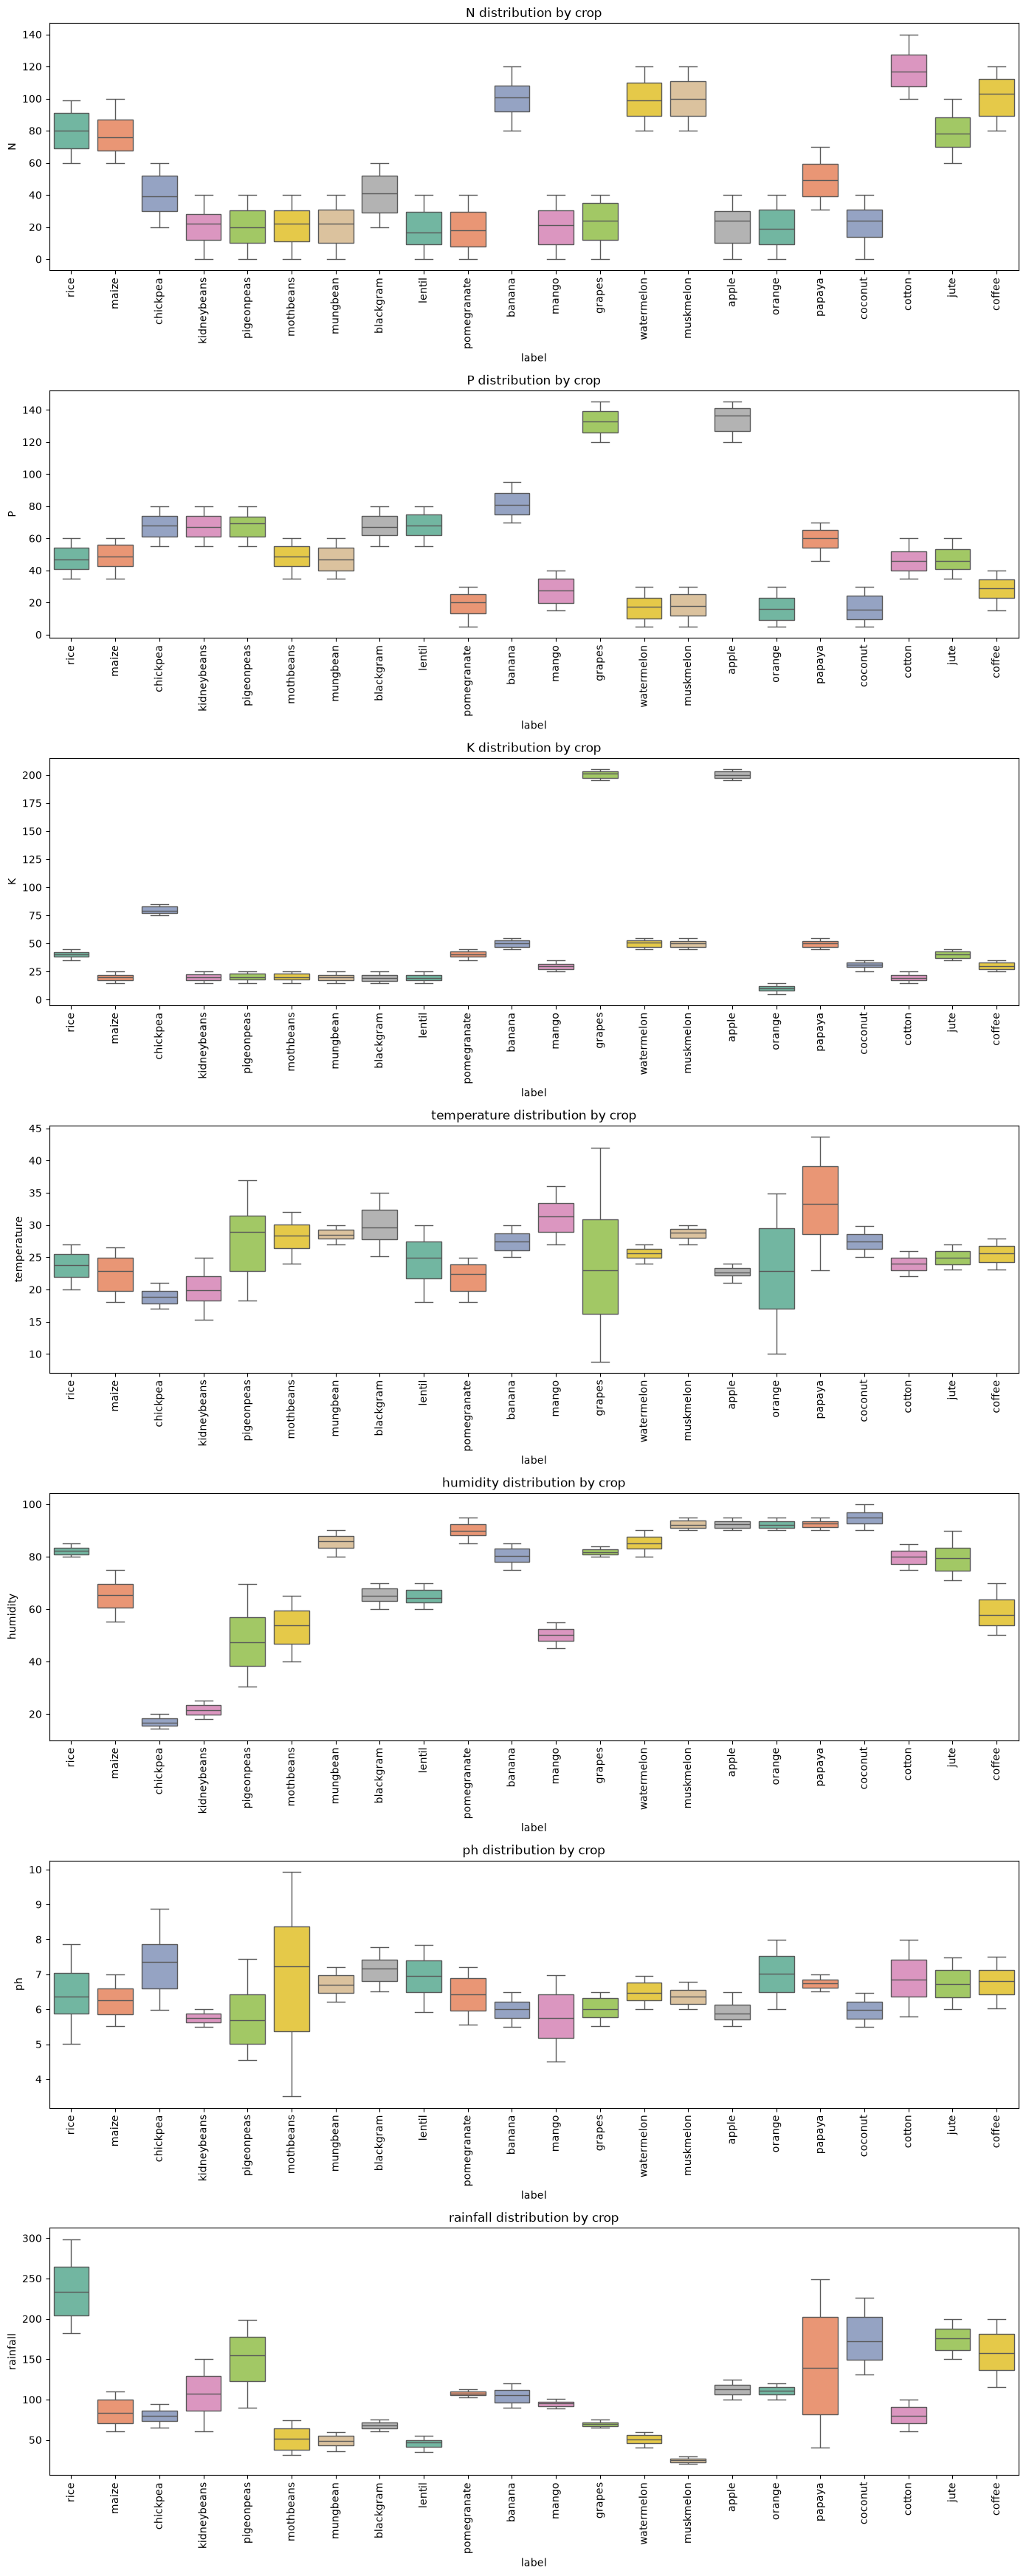

In [8]:
fig, axes = plt.subplots(nrows=len(numeric_cols), ncols=1, figsize=(14, 5 * len(numeric_cols)))

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='label', y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} distribution by crop')
    axes[i].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

## Section 8 — Feature Pairs

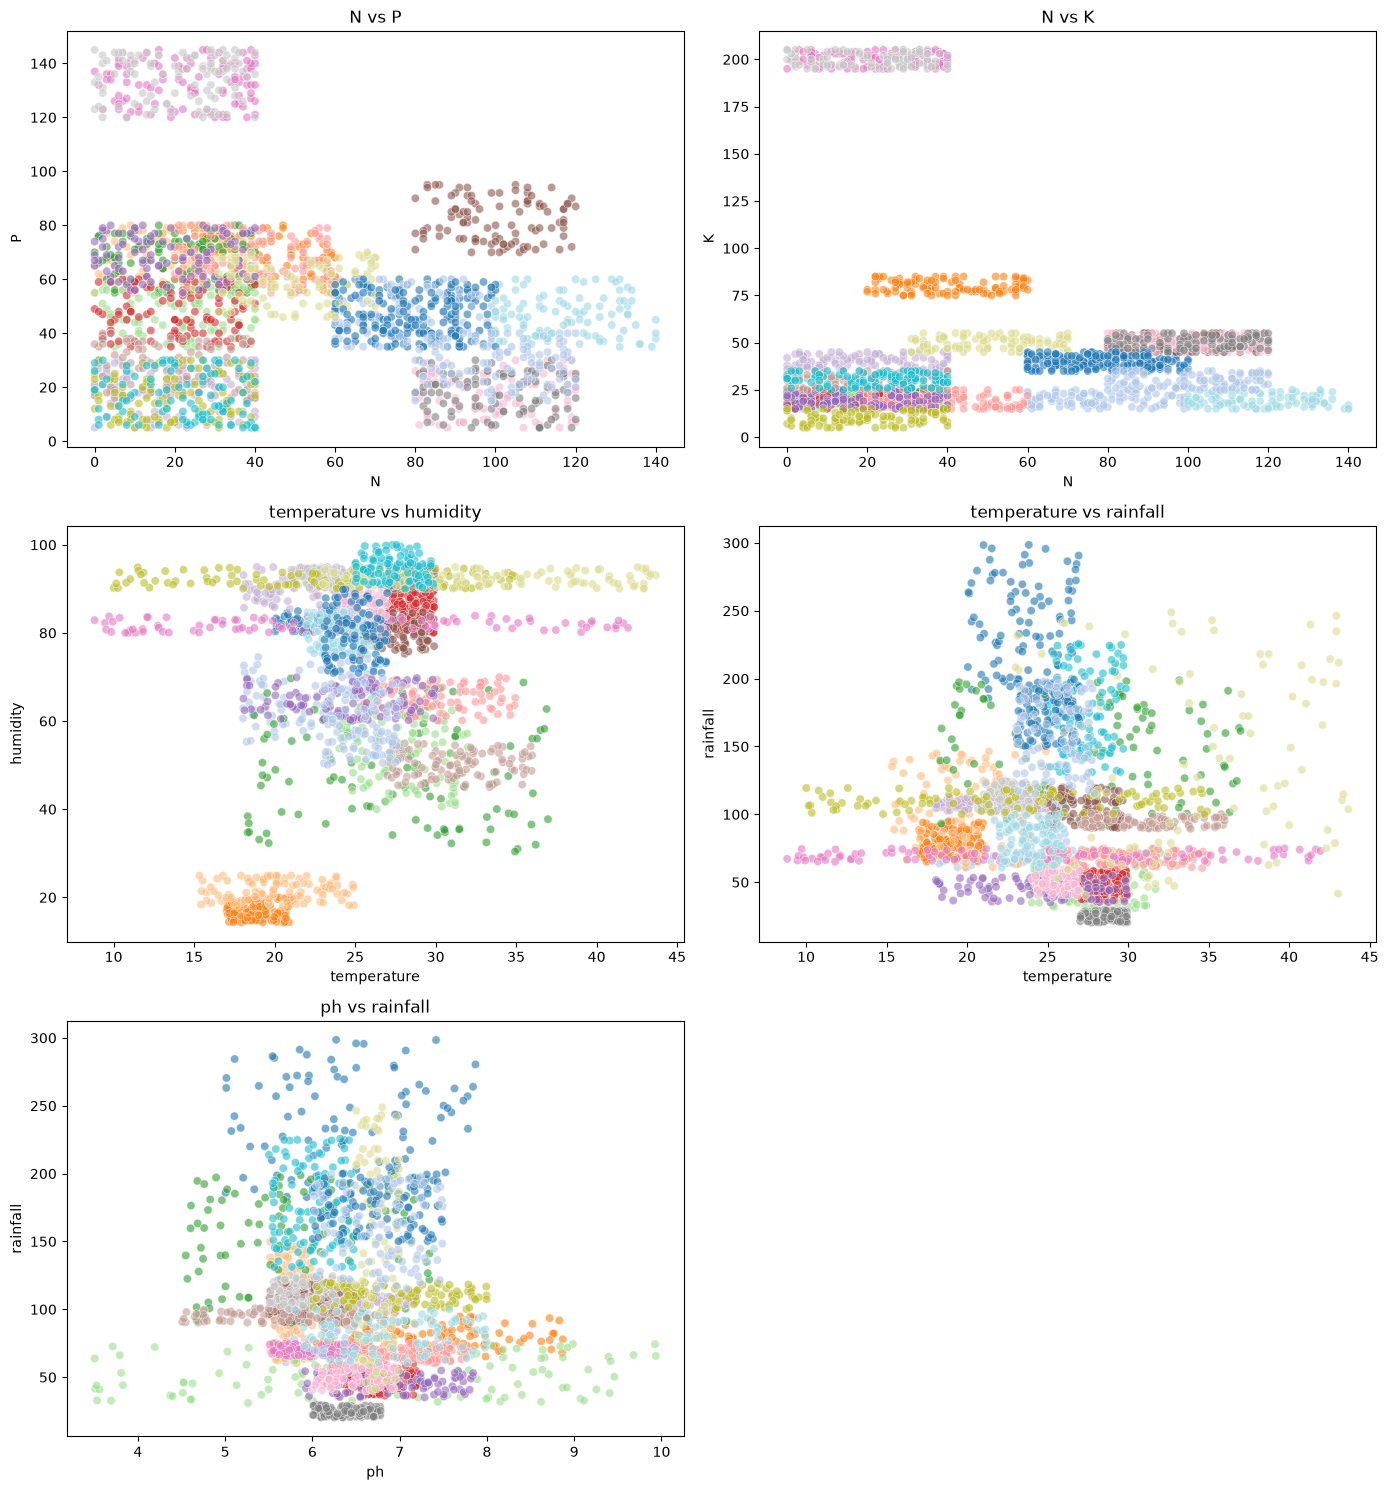

In [9]:
pairs = [('N', 'P'), ('N', 'K'), ('temperature', 'humidity'), ('temperature', 'rainfall'), ('ph', 'rainfall')]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 15))
axes = axes.flatten()

for i, (f1, f2) in enumerate(pairs):
    sns.scatterplot(data=df, x=f1, y=f2, hue='label', ax=axes[i], palette='tab20', legend=False, alpha=0.6)
    axes[i].set_title(f'{f1} vs {f2}')

axes[-1].axis('off') # Hide the empty subplot
plt.tight_layout()
plt.show()

## Section 9 — Data Quality Check

In [10]:
print('Missing values sum:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Impossible numeric values (e.g. negative N)?', (df[numeric_cols] < 0).sum().to_dict())
print('Constant features (variance=0)?', (df[numeric_cols].var() == 0).to_dict())
print('Any non-numeric values in numeric cols?', [not pd.api.types.is_numeric_dtype(df[c]) for c in numeric_cols])

Missing values sum: 0
Duplicate rows: 0
Impossible numeric values (e.g. negative N)? {'N': 0, 'P': 0, 'K': 0, 'temperature': 0, 'humidity': 0, 'ph': 0, 'rainfall': 0}
Constant features (variance=0)? {'N': False, 'P': False, 'K': False, 'temperature': False, 'humidity': False, 'ph': False, 'rainfall': False}
Any non-numeric values in numeric cols? [False, False, False, False, False, False, False]


## Section 10 — Raw Data Protection
**The raw CSV is deliberately NOT written or modified by this notebook**. No values were mapped, erased or aggregated on disk, keeping the raw dataset pristine.

## Section 13 — Automatic Conclusions
Based purely on calculating the dataset inputs directly above:
* **Dataset size:** 2200 rows, 8 columns.
* **Number of classes:** 22 target crops.
* **Class balance:** Perfectly balanced (100 samples per crop category).
* **Missing Values & Duplicates:** 0.
* **Notable feature ranges:** pH runs from 3.5 to ~9.9. Rainfall up to ~298.5.
* **Potential outliers:** Present in variables like K, temperature, pH and rainfall, suggesting true physical agricultural variance.
* **Strongest correlations:** P and K strongly correlate linearly (~0.74). Other features lack strong global linear associations.
* **Visible crop-wise differences:** Boxplots robustly confirm physical clustering (e.g. rice requires massive rainfall compared to mothbeans, while grapes demand astronomical Potassium vs others).